# 1. Problem: reconstruct a quantum operation

A process acts on a quantum state; it is a different unknown from the state itself. Auxiliary-qubit interferometry scans a sphere to recover the operation's scalar/vector phase-space functions. This notebook actively reconstructs **all 50 directions, both ranks and all four controls**. The nominal Hadamard design in the paper is not actual truth and is not used by either reconstruction.

The primary result is the published fixed-step weighted-droplet method. An optimization of the published objective is freshly computed alongside the independently reproduced original. There is no default cache preview.

## Current benchmark contract v2

The v2 evaluator independently forms all eight complex expected channels on the 50-direction Lebedev grid, with the public quadrature weights. Weighted mean squared observable error may exceed the attainable fit by at most 1e-6; the original unitarity boundary 1e-6 remains. Global unitary phase is a gauge. An independently optimized quaternion with lower real-data loss passes; a wrong Pauli operation fails. The conditional ideal-unitary fit is not independent process truth. The cleaned reconstruction algorithm is unchanged. Historical displayed method-identity numbers describe v1 and are not current pass boundaries.


In [1]:
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').exists(): root=root.parent
assert (root/'src').exists()
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct,optimize_comparison
from src.visualization import observations,process_comparison,process_metrics,residuals,droplet_surface
from src.physics_model import matrix_quaternion
start=time.perf_counter()
data=load_data(root/'data/raw_data.npz')
upstream=np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False)
print('Measured complex values:',data['expectation'].size,'directions:',len(data['polar_angle']))

Measured complex values: 400 directions: 50


# 2. Data: measured channels, not invented counts

The author archive `expec_H.mat` supplies 8 complex expectation channels at 50 Lebedev points. Applying the original optimization initialization gives (0.39368072, 0.18679134, 0.40349409, 0.05813852), matching the paper's experimental Appendix F.1 rounded values. This independently identifies the dataset despite a separate acquisition-example notebook defaulting to simulation.

Each complex expectation combines two complementary measurements. The processed archive does not provide raw shots or variances, so no Gaussian uncertainty or synthetic count error bars are fabricated. All device attenuation and offsets remain in the visible data.

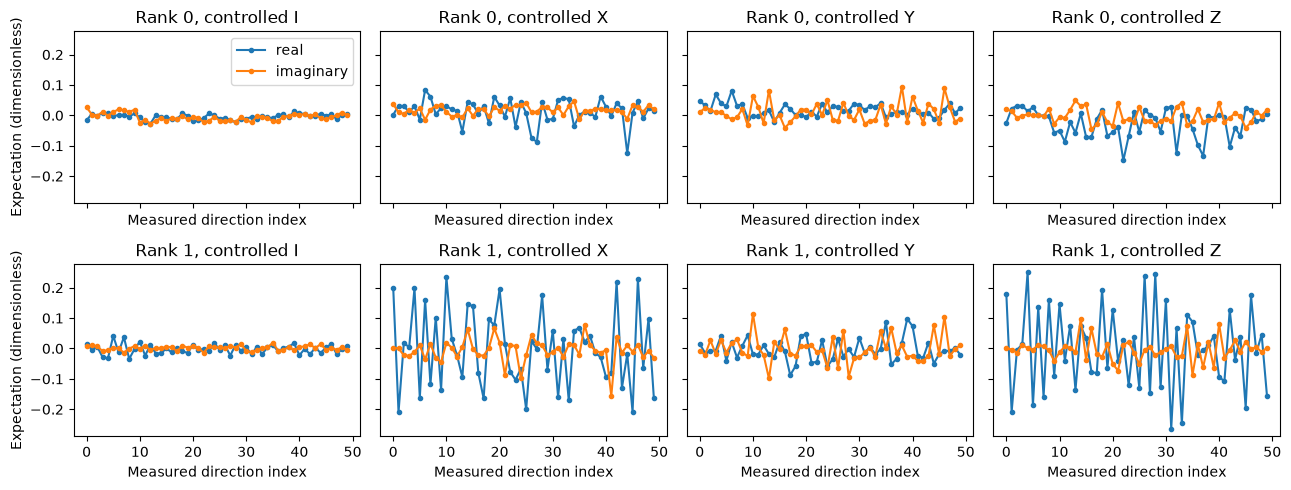

In [2]:
observations(data)
plt.show()

# 3. Physics: spherical harmonics and unitary structure

Write $U=D I+i(A X+B Y+C Z)$ with real normalized quaternion $q=(A,B,C,D)$. Here $I$ is identity and $X,Y,Z$ are Pauli matrices. At direction $n$, let $v=(A,B,C)\cdot n$. Ideal rank components obey

$$e_{0,I}=D^2,\quad e_{1,I}=iDv,\quad e_{0,j}=-iq_jD,\quad e_{1,j}=q_jv.$$

The index $j$ labels controlled $X,Y,Z$ reference operations. Their measured functions are proportional to components of the unknown process, with hardware errors perturbing these relations. The normalized degree-zero/one basis is $b=(\sqrt{3/(32\pi)}n_x,\sqrt{3/(32\pi)}n_y,\sqrt{3/(32\pi)}n_z,1/\sqrt{32\pi})$. Lebedev weights integrate a sphere average, so $\sum w=1$. This independent physical identity is tested for arbitrary unitary processes, while the benchmark reconstruction always uses measured observations.

# 4. Method: combine measured droplets

Combine scalar/vector ranks as $(e_0+\sqrt{3}e_1)/(4\sqrt{2\pi})$, reorder controls to X,Y,Z,I and multiply the first three functions by $i$. Weighted correlations initialize quaternion magnitudes and signs. Project the quaternion-weighted combined function onto the four basis functions, retain imaginary vector coefficients and the real scalar coefficient, then normalize. The standard method performs the original nine updates after the initial projection.

The active optimization comparison minimizes $J=\frac12\sum_j\|M_j-q_j U(q)\|_F^2$, where $M_j$ is the author's normalized per-channel matrix. Both original and fresh computations use this exact objective; Octave fminunc and SciPy BFGS have different trajectories. The original sign routine's final branch overrides its earlier branches; the local implementation preserves that behavior.

Fresh primary seconds: 0.00036319997161626816 fresh optimized seconds: 0.007570900022983551
Fresh optimizer diagnostic: Desired error not necessarily achieved due to precision loss.
Objective difference from reproduced original: -1.7763568394002505e-15


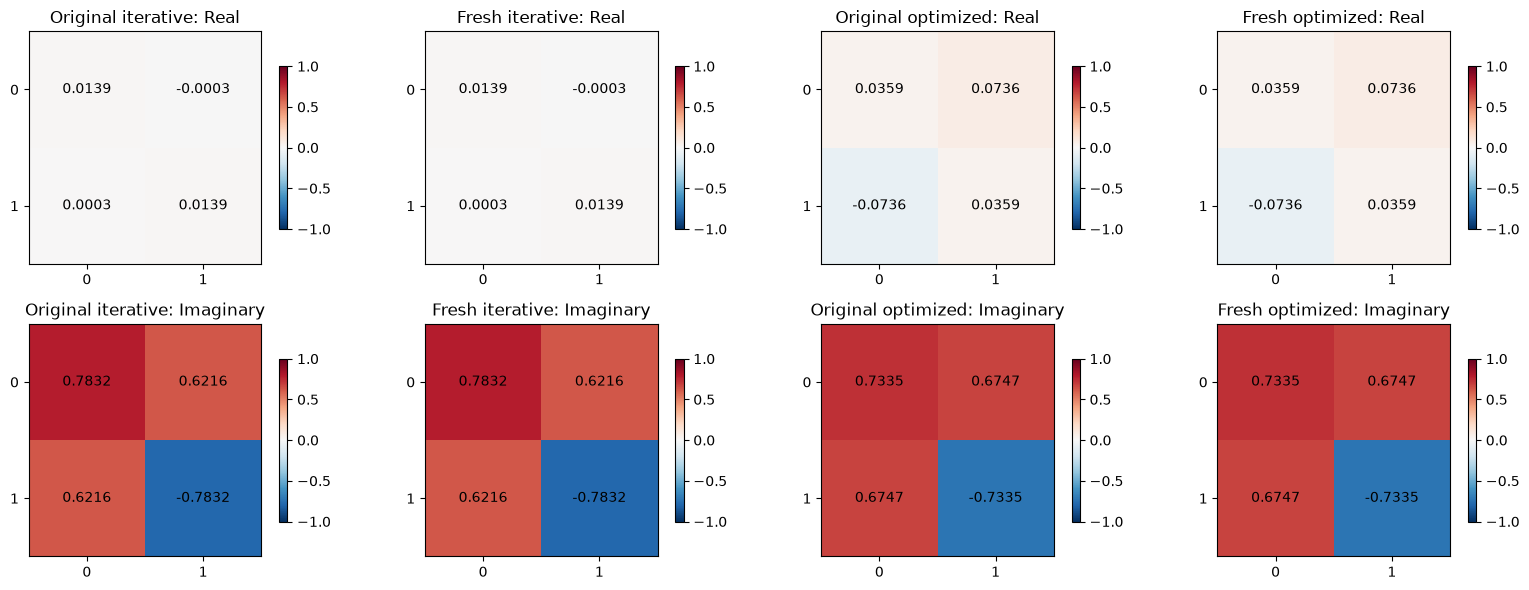

In [3]:
tic=time.perf_counter()
fresh=reconstruct(data)
primary_seconds=time.perf_counter()-tic
tic=time.perf_counter()
optimized=optimize_comparison(data)
optimized_seconds=time.perf_counter()-tic
print('Fresh primary seconds:',primary_seconds,'fresh optimized seconds:',optimized_seconds)
print('Fresh optimizer diagnostic:',optimized['message'])
print('Objective difference from reproduced original:',optimized['objective'][-1]-upstream['optimized_cost'][-1])
process_comparison([upstream['reconstruction'],fresh['reconstruction'],upstream['optimized_reconstruction'],optimized['reconstruction']],['Original iterative','Fresh iterative','Original optimized','Fresh optimized'])
plt.show()

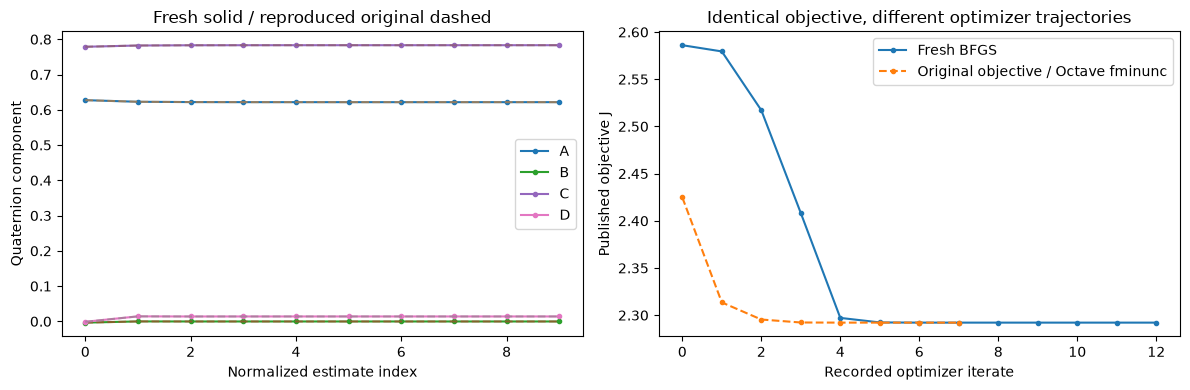

In [4]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
for j,name in enumerate(['A','B','C','D']):
    ax[0].plot(fresh['quaternion_history'][:,j],'.-',label=name)
    ax[0].plot(upstream['quaternion_history'][:,j],'--',alpha=.5)
ax[0].set(xlabel='Normalized estimate index',ylabel='Quaternion component',title='Fresh solid / reproduced original dashed');ax[0].legend()
ax[1].plot(optimized['objective'],'.-',label='Fresh BFGS')
ax[1].plot(upstream['optimized_cost'],'.--',label='Original objective / Octave fminunc')
ax[1].set(xlabel='Recorded optimizer iterate',ylabel='Published objective J',title='Identical objective, different optimizer trajectories');ax[1].legend();fig.tight_layout();plt.show()

# 5. Results: reference parity, ablations and residuals

Reference agreement measures implementation parity, not physical accuracy. The independent original iterative and optimization runs are separately identified; paper-reported optimized quaternion values are historical and are not substituted for either run. The primary physical unitary constraint is checked independently.

The following ablations are freshly reconstructed: scalar rank removed, vector rank removed, and every second direction retained. The last ablation renormalizes the retained quadrature weights; it intentionally disrupts full-grid quadrature and is not the benchmark input. No missing method is represented by zero.

Method | phase-aligned RMS vs original iterative | unitarity defect
Fresh iterative              6.662975544e-16 3.141198704e-16
Fresh optimized              0.07489840452 3.142121389e-16
Scalar rank removed          0.0372892021 7.950861425e-18
Vector rank removed          0.9635790585 1.355663043e-18
Alternating directions       0.06010449228 3.165516652e-16


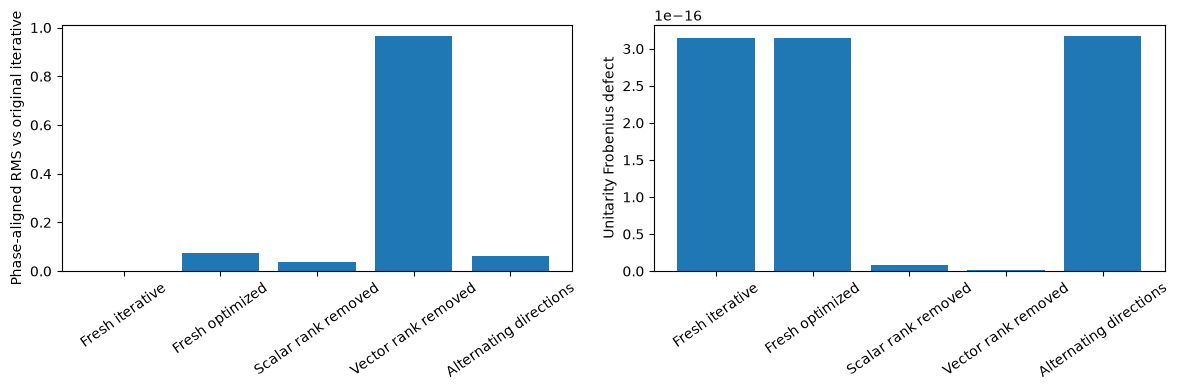

In [5]:
ablations={}
for label,rank in [('Scalar rank removed',0),('Vector rank removed',1)]:
    d={k:v.copy() for k,v in data.items()};d['expectation'][rank]=0
    ablations[label]=reconstruct(d)['reconstruction']
d={k:v[...,::2].copy() for k,v in data.items()};d['quadrature_weight']/=d['quadrature_weight'].sum()
ablations['Alternating directions']=reconstruct(d)['reconstruction']
labels=['Fresh iterative','Fresh optimized']+list(ablations)
matrices=[fresh['reconstruction'],optimized['reconstruction']]+list(ablations.values())
metrics=[process_metrics(u,upstream['reconstruction']) for u in matrices]
print('Method | phase-aligned RMS vs original iterative | unitarity defect')
for name,m in zip(labels,metrics):print(f"{name:28s} {m['phase_aligned_process_rmse']:.10g} {m['unitarity_error']:.10g}")
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].bar(labels,[m['phase_aligned_process_rmse'] for m in metrics]);ax[0].set_ylabel('Phase-aligned RMS vs original iterative')
ax[1].bar(labels,[m['unitarity_error'] for m in metrics]);ax[1].set_ylabel('Unitarity Frobenius defect')
for a in ax:a.tick_params(axis='x',rotation=35)
fig.tight_layout();plt.show()
np.savez_compressed(root/'notebooks/reference_outputs/fresh_measurements.npz',reconstruction=fresh['reconstruction'],optimized_reconstruction=optimized['reconstruction'],quaternion_history=fresh['quaternion_history'],optimized_cost=optimized['objective'],ablation_matrices=np.stack(list(ablations.values())),phase_aligned_rmse=np.array([m['phase_aligned_process_rmse'] for m in metrics]))

Diagnostic residuals: {'ideal_residual_rms': 0.152205065354819, 'gain_adjusted_diagnostic_rms': 0.048414243995842654}


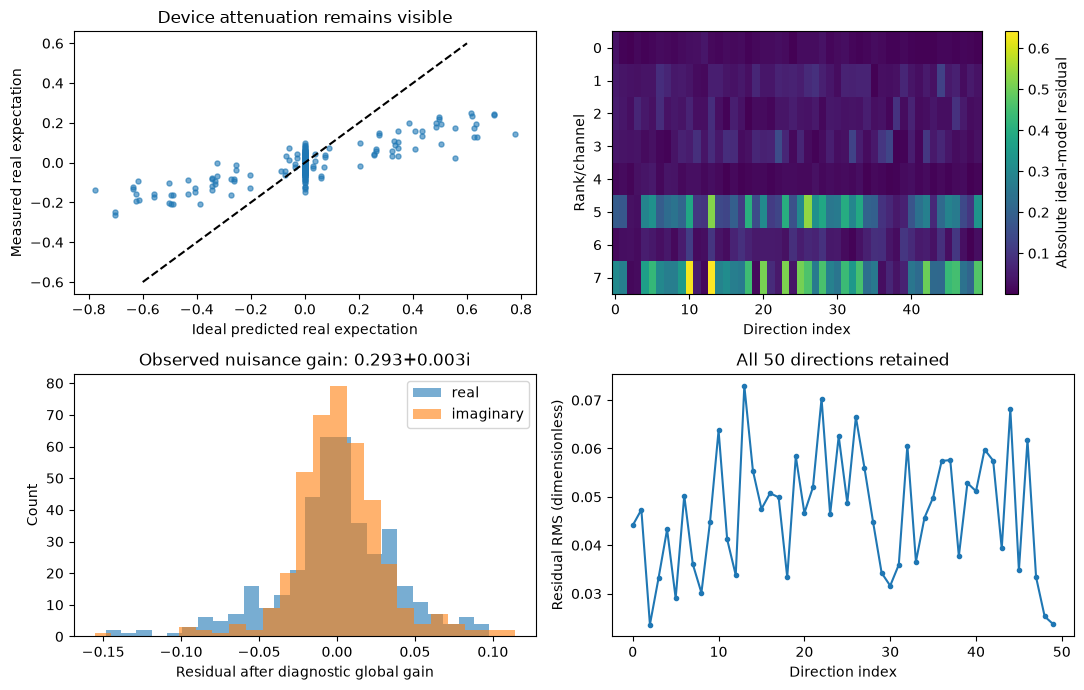

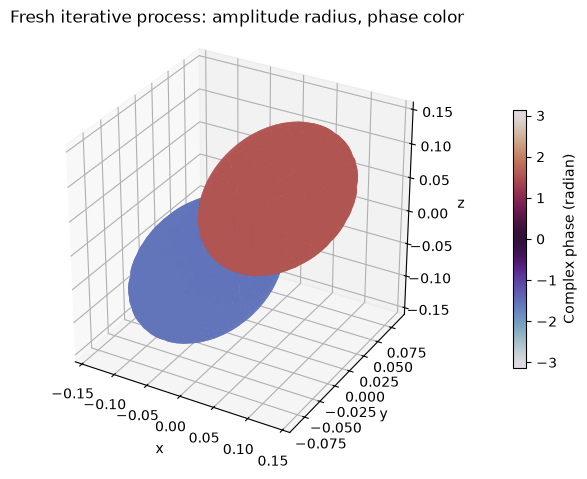

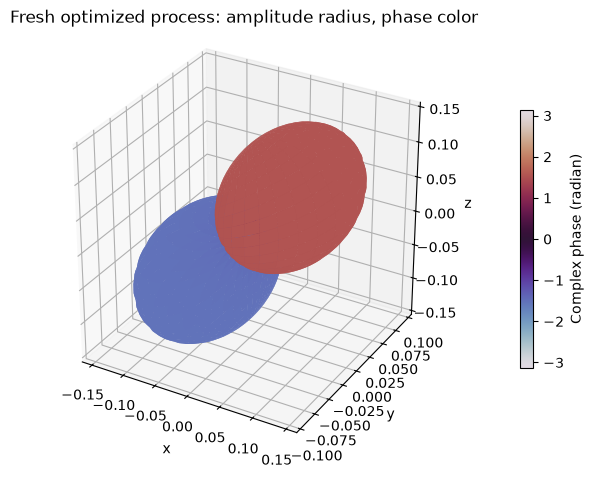

In [6]:
figure,residual_metrics=residuals(data,fresh['reconstruction'])
print('Diagnostic residuals:',residual_metrics)
plt.show()
droplet_surface(fresh['reconstruction'],'Fresh iterative process: amplitude radius, phase color')
plt.show()
droplet_surface(optimized['reconstruction'],'Fresh optimized process: amplitude radius, phase color')
plt.show()

# 6. Conclusion and limits

The complete experimental scan is reconstructed actively using only cleaned local mathematics. The primary output reproduces the original fixed-step method and satisfies a unitary process constraint. Optimization reaches the original objective minimum but need not coincide with the iterative result; all comparisons are shown rather than merged into a single claimed truth.

Ideal-acquisition residuals visibly retain device attenuation and offsets. A global gain fitted only for residual diagnosis is not calibration supplied to the solver. These measurements support validation of the published reconstruction, not a claim that either estimated unitary equals the actual noisy hardware channel. The final metrics below evaluate the fresh primary output and record notebook runtime.

In [7]:
import importlib.util
spec=importlib.util.spec_from_file_location('standalone_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
(root/'output').mkdir(exist_ok=True)
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=fresh['reconstruction'])
report,exit_code=judge.evaluate(root/'output/reconstruction.npz')
print(json.dumps(report,indent=2))
assert exit_code==0
print('Notebook active computation seconds:',time.perf_counter()-start)

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "phase_aligned_process_rmse": 6.6629755435415765e-16,
    "unitarity_error": 3.1411987038228775e-16
  },
  "thresholds": {
    "phase_aligned_process_rmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "unitarity_error": {
      "comparison": "<=",
      "boundary": 1e-06
    }
  },
  "errors": []
}
Notebook active computation seconds: 1.3168297000229359
